# N115: terminal J with health constraints at both steps

Status: **complete**.

N115 is the controlled terminal-cost comparison against completed N114. Restore
the SAME ORIGINAL image-model/optimizer/RNG parent for all 91,968 reserved ordered
images. Do not continue N114 weights. All 4,032 offline images remain excluded.
Reuse TRAIN-only four-head predictor/transforms, prior and validation calibration
byte-for-byte. TEST is inherited diagnostics only. Rates stay {0, 1/8, 1/4} of
original nominal LR. The 88 rich features, fixed-context propagation, stagewise
health-floor fractions/ratchet, adaptive uncertainty, seeds, 5% feasible-action
exploration, feedback rule and 384-arrival readouts/checkpoints are unchanged.

The ONLY controller change is the horizon objective in BOTH decision routes:

| Decision | N114 reference | N115 |
| --- | --- | --- |
| Ordinary model-based H2 plan | minimize predicted J_first + J_second | minimize predicted J_second |
| Measured copied H2 sequence | measured sum < 2*J_before - 1e-6 | measured J_second < J_before - 1e-6 |
| Ranking passing copied sequences | minimum measured sum | minimum measured terminal J |

Both predicted health lower bounds must pass at BOTH steps. Both actual copied
health measurements must retain BOTH frozen pre-decision health floors. A lower
terminal objective cannot excuse an intermediate health breach. First-step J may
temporarily increase. Predictor targets stay actual one-step delta-J and the
three metric changes; no relabeling, refitting or target rescaling is introduced.

Preserve the 512-blocked-arrival trigger, then every 256 blocked arrivals, and
six positive-first copied sequences (a,b), a in {1/8,1/4}, b in {0,1/8,1/4}.
Four paths have two actual updates, two are train/skip. Reuse shared first states,
so six copied updates per complete audit. The second virtual update repeats the
CURRENT image with the exact same distinct augmentation-seed namespace as N114,
paired across rates. No future real image is read. Actual model and Adam state
evolve inside copies. Commit ONLY the selected FIRST state, discard the second,
then replan at the next real arrival. A fixed-context endpoint improvement is
scenario evidence, not a guarantee for the next actual image.

Valid measured FIRST-step copied targets alone adapt the predictor exactly as
N114: one forgetting tick and total weight one per audit parent. Second copied
transitions are diagnostics only, never training labels or calibration samples.
Anchors advance only on committed plant updates. Failed trials provide no labels.
Temporary weights remain in memory; only the committed learner is checkpointed.

Run after N114 releases its worker lease and finishes verification. The notebook
compares only N114 summed-J and N115 terminal-J. A read-only historical diagnostic
applies the new criterion to N114's already-measured copied paths, clearly labeled
as a same-state counterfactual rather than a new policy trajectory. It cannot fit
the predictor, tune thresholds or alter calibration. These development streams
have been inspected previously; this is not fresh confirmatory evidence.

Preflight uses offline TRAIN images only. Validate objective ranking differences,
endpoint gains despite temporary J deterioration, health constraints at both
stages, failed-path masking, exact committed first-state equality, rejected-copy
isolation, exact full/resumed GPU continuation and causal replay of every decision,
predictor update, margin, anchor, starvation clock and RNG state.


| Arm | Saved images | Plant updates | Predictor feedback arrivals | Available late probe (%) | Recorded time (min) |
| --- | ---: | ---: | ---: | ---: | ---: |
| N114  -  Summed J H2 | 91,968 | 3,531 | 3,717 | 62.859 | 51.76 |
| N115 - Terminal J H2 | 91,968 | 1,305 | 1,613 | 63.667 | 55.62 |

Current run coverage: **91,968**. Available table means use each arm's saved coverage; primary comparisons use common scheduled30k--91,968 checkpoints.

## Positive-update one-step forecast RMSE

| Arm | Output | Active model | Frozen shadow, same states/actions | Persistence | Positive updates |
| --- | --- | ---: | ---: | ---: | ---: |
| N114  -  Summed J H2 | RankMe | 0.0047411 | 0.00591774 | 0.00820173 | 3,531 |
| N114  -  Summed J H2 | Reconstruction loss | 0.000401917 | 0.000829227 | 0.00069085 | 3,531 |
| N114  -  Summed J H2 | Variance | 1.95267e-05 | 3.10643e-05 | 3.70869e-05 | 3,531 |
| N115 - Terminal J H2 | RankMe | 0.00603295 | 0.00743299 | 0.0103685 | 1,305 |
| N115 - Terminal J H2 | Reconstruction loss | 0.00057449 | 0.000877824 | 0.00105362 | 1,305 |
| N115 - Terminal J H2 | Variance | 2.04314e-05 | 3.46984e-05 | 4.44654e-05 | 1,305 |

RMSE is in native metric units. Different policies visit different states; the frozen-shadow comparison is paired within each plant trajectory. Per-action and two-step numbers/counts are saved in comparison.json.

## Historical same-state comparison

On 203 already measured N114 audit states, the terminal criterion permits 23 first-step re-entries versus 17 for summed J. This counterfactual does not represent the new policy trajectory and is never used for fitting or tuning.


## Balanced audit linear accuracy (%)

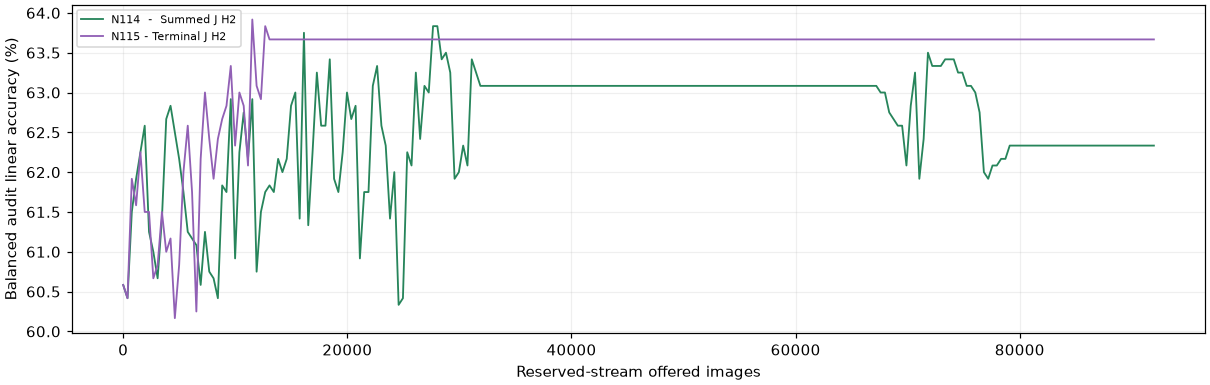



## RankMe

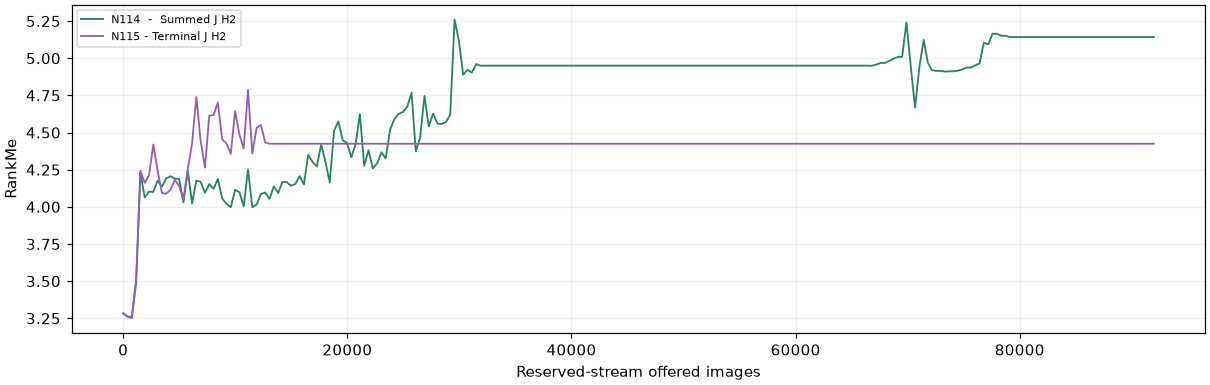



## Fixed-bank reconstruction loss

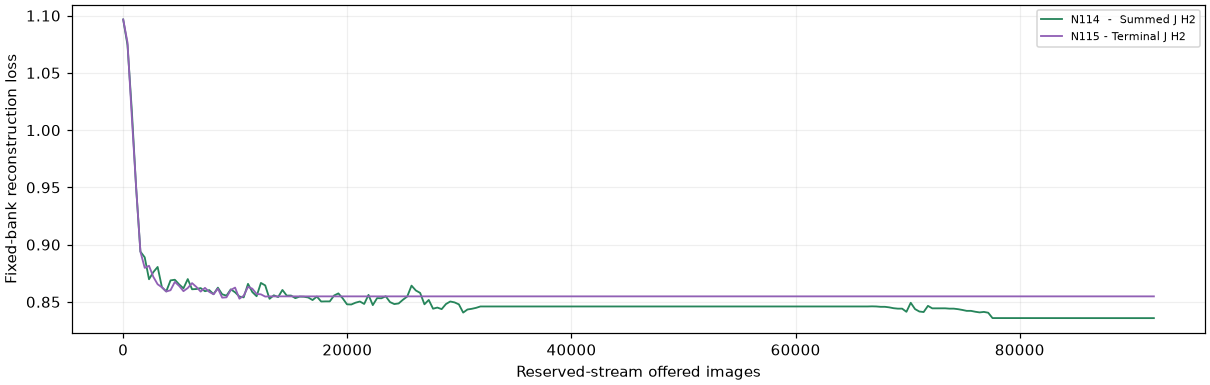



## Variance

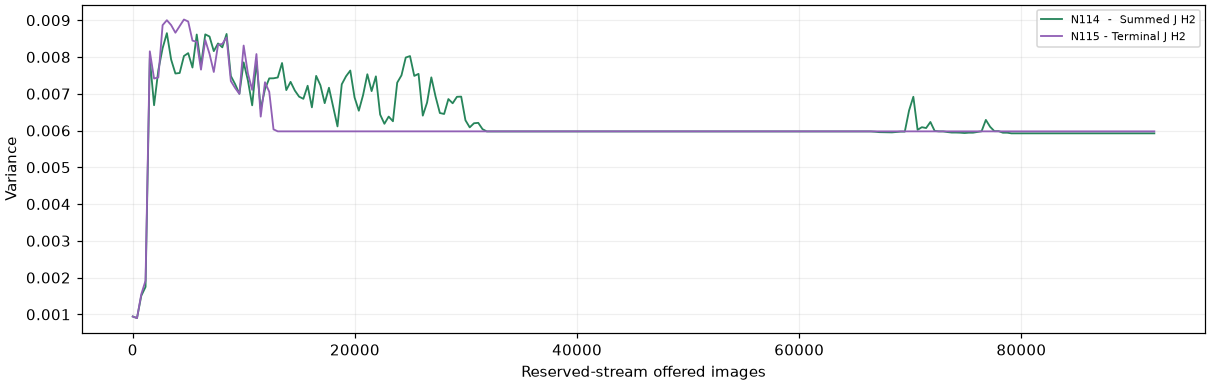



## Original fixed-bank J

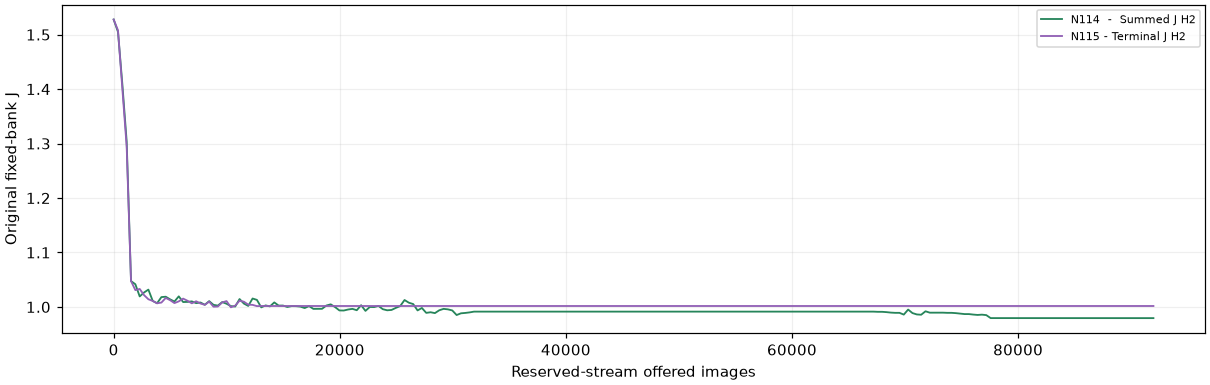



## Covariance

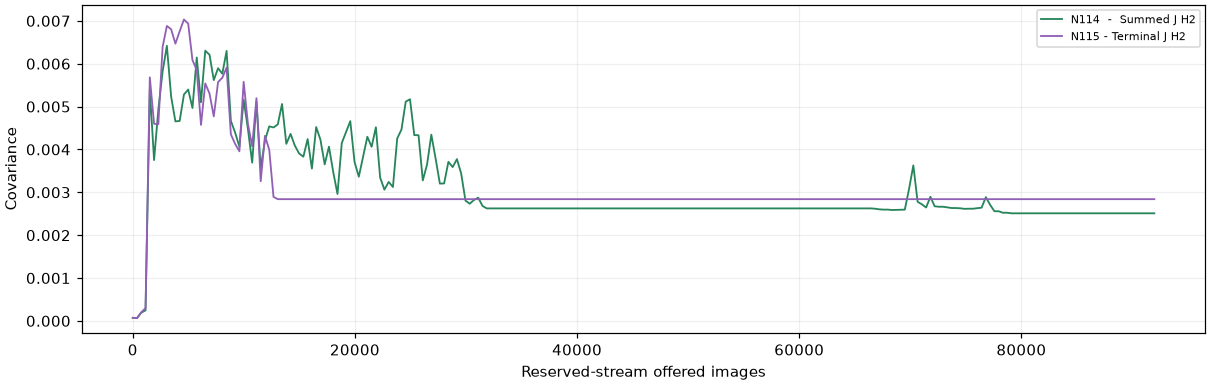



## Actual plant outputs and one-step forecasts

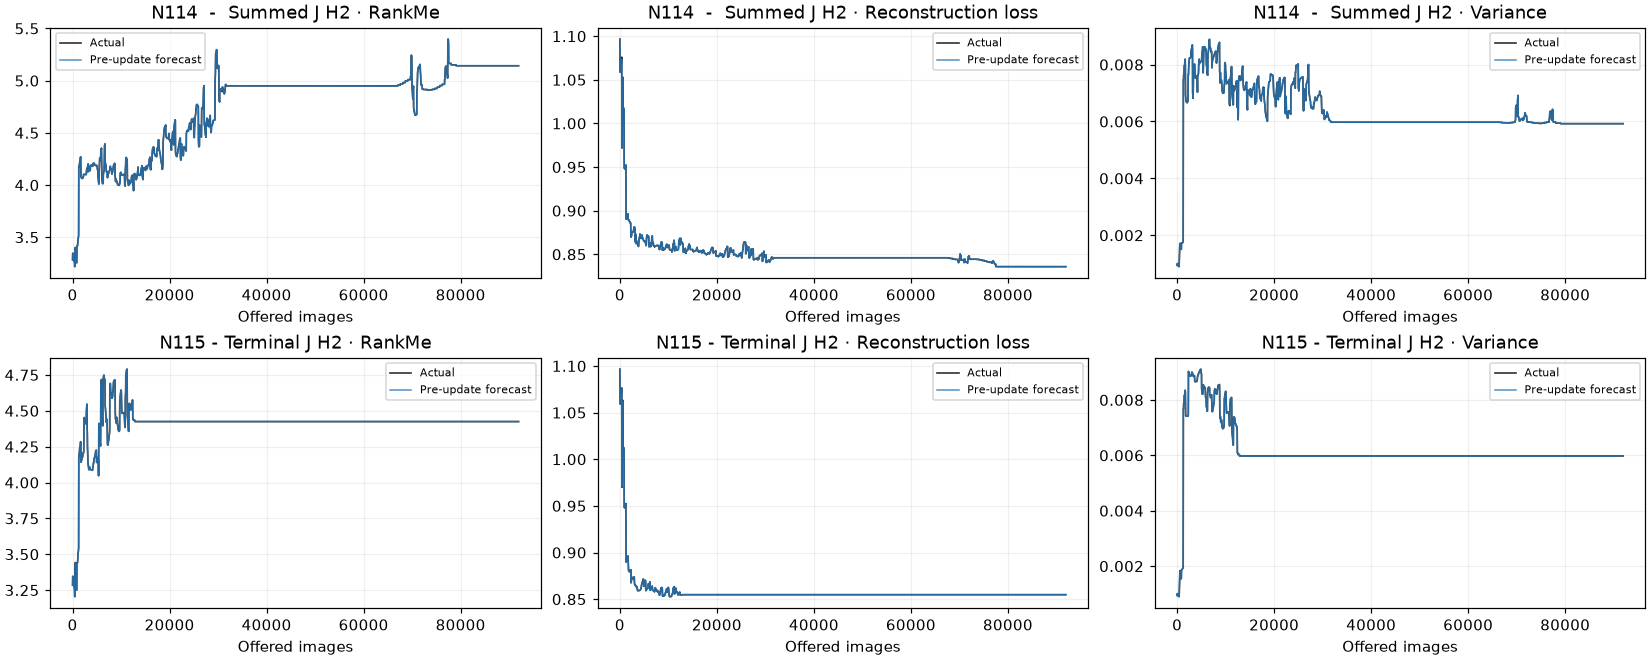

Display subsamples every32 arrivals; RMSE uses all successful positive updates and excludes identity skips.

## One-step positive-update RMSE

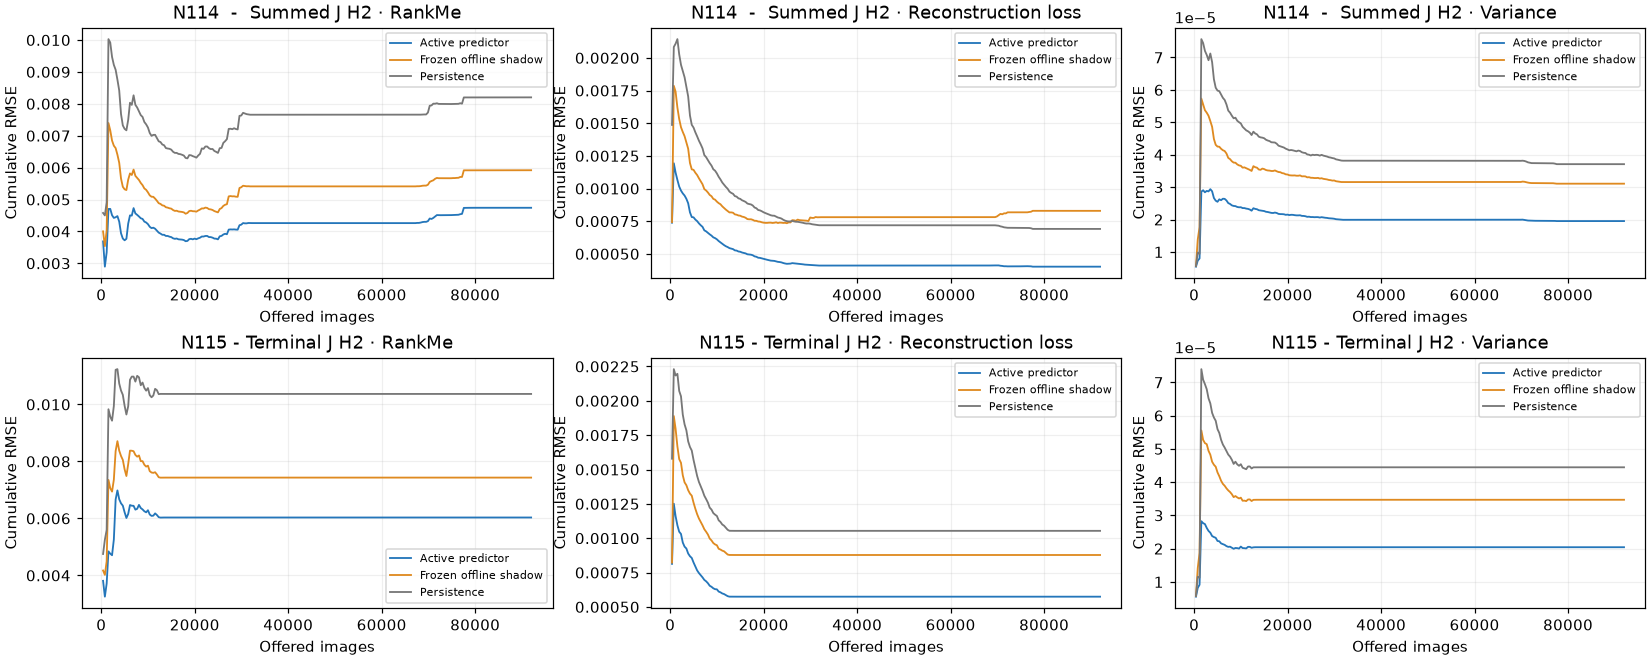



## Two-step nontrivial-window RMSE

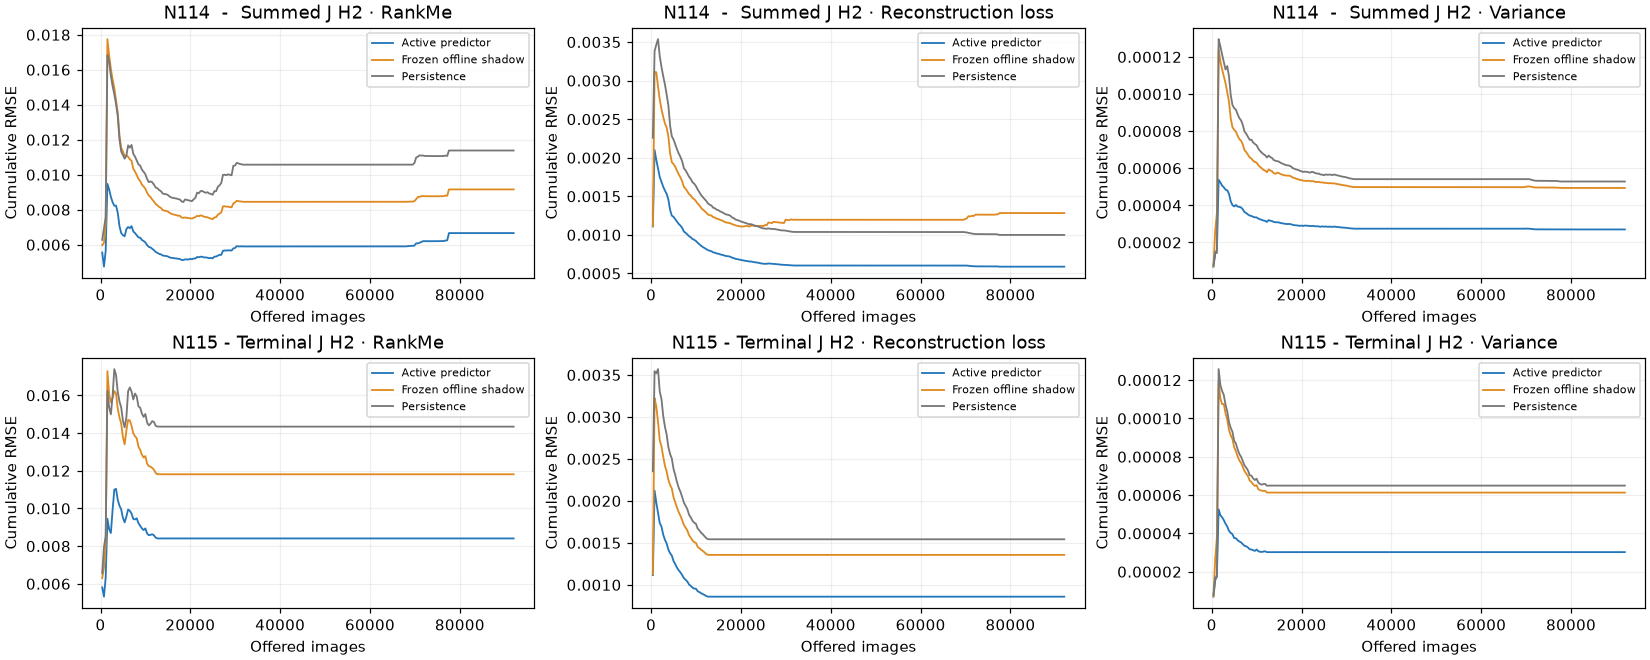



## Plant update and rate budgets

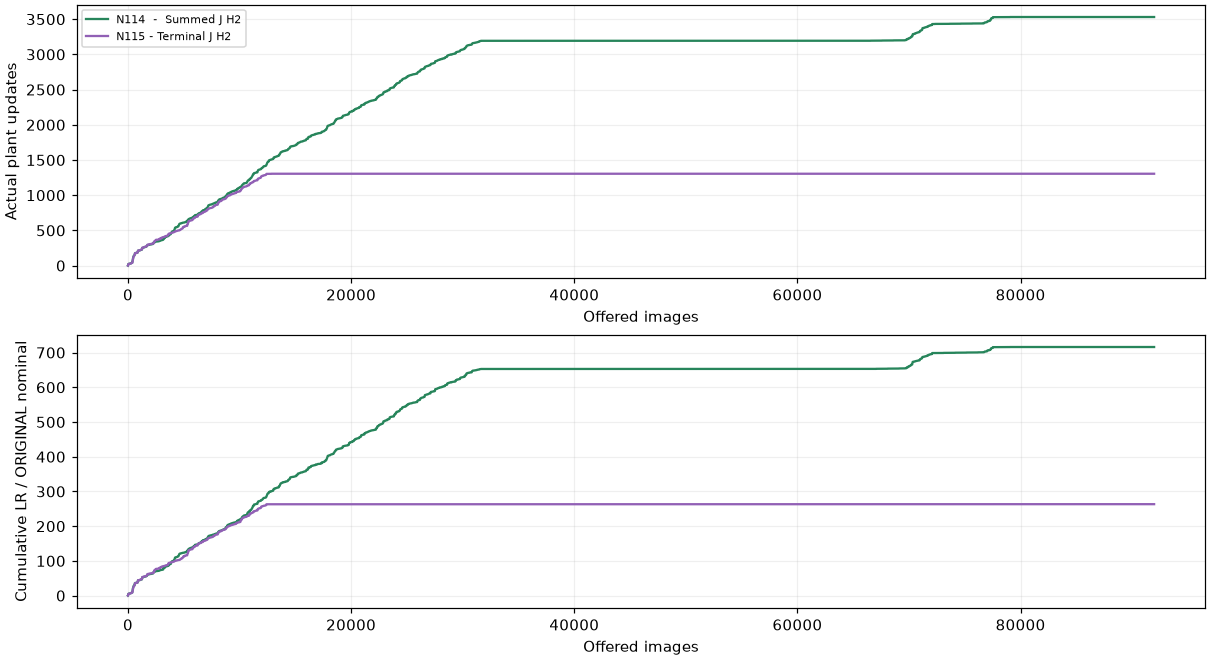



## Transition-model adaptation

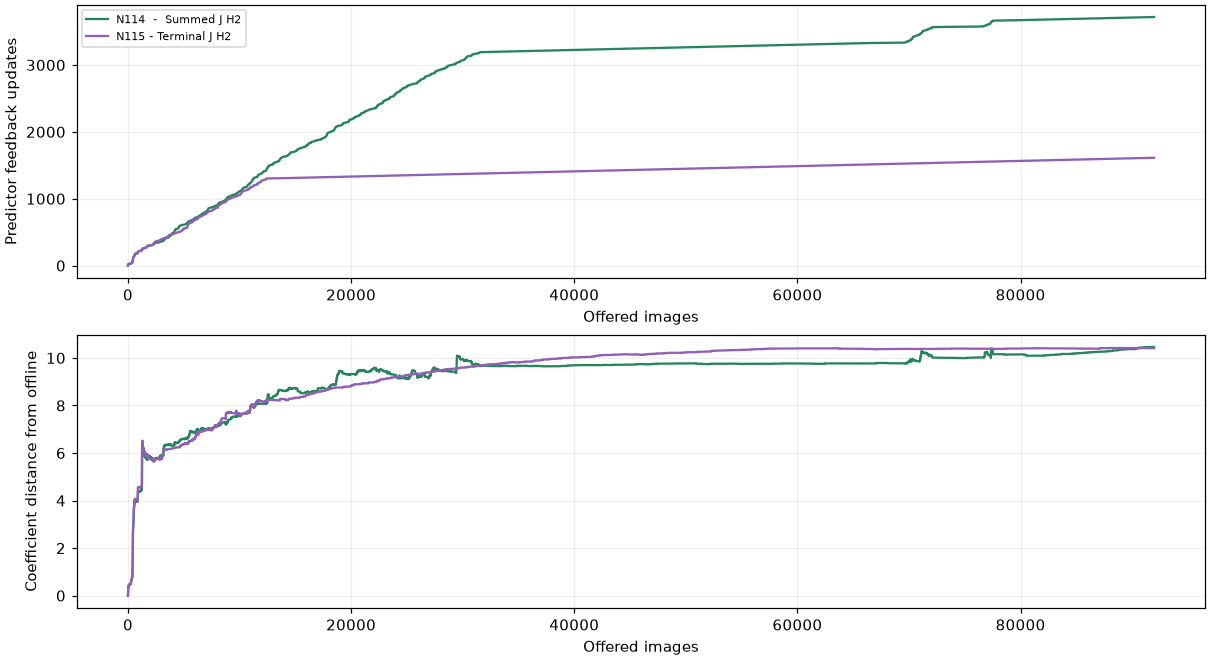



## Executed learning-rate actions

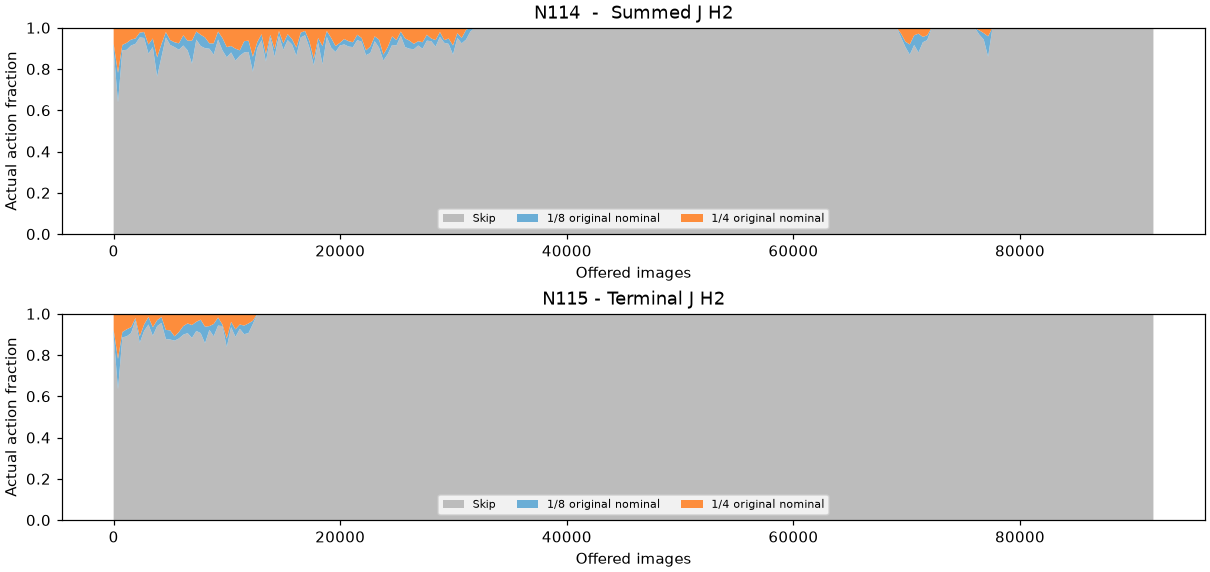



## Actual trained-image losses

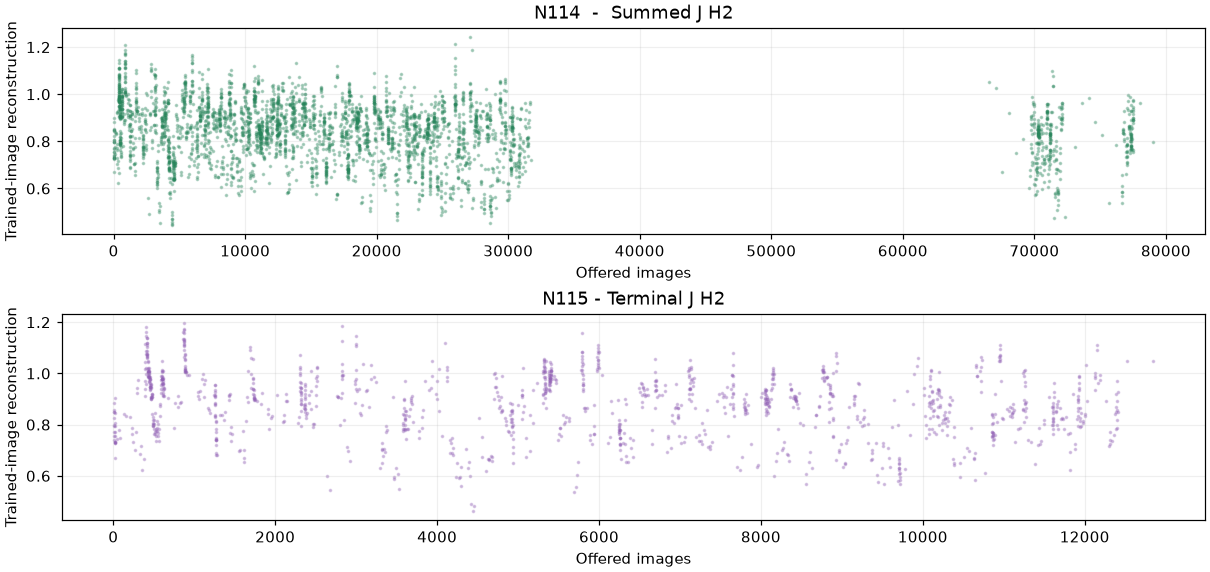



## Audit: linear task metrics

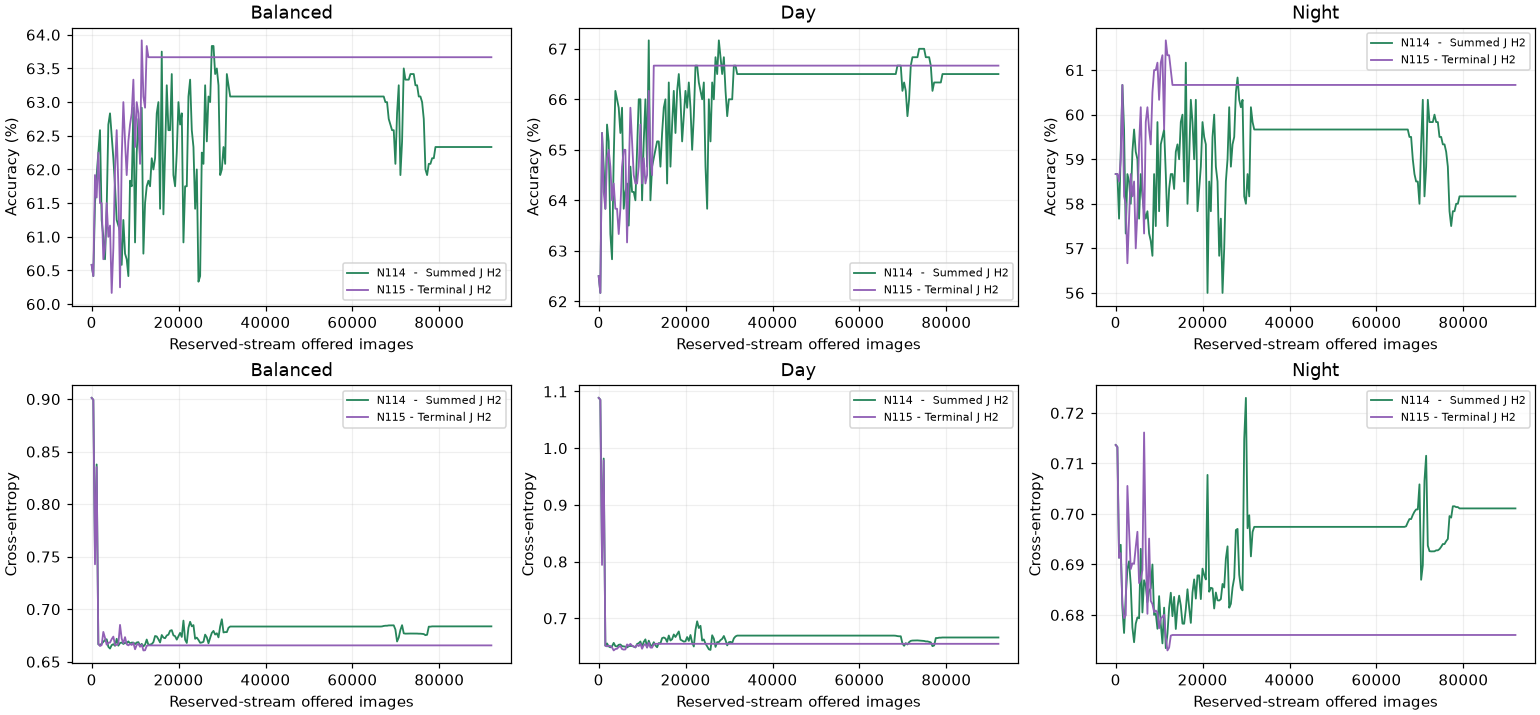



## Audit: knn task metrics

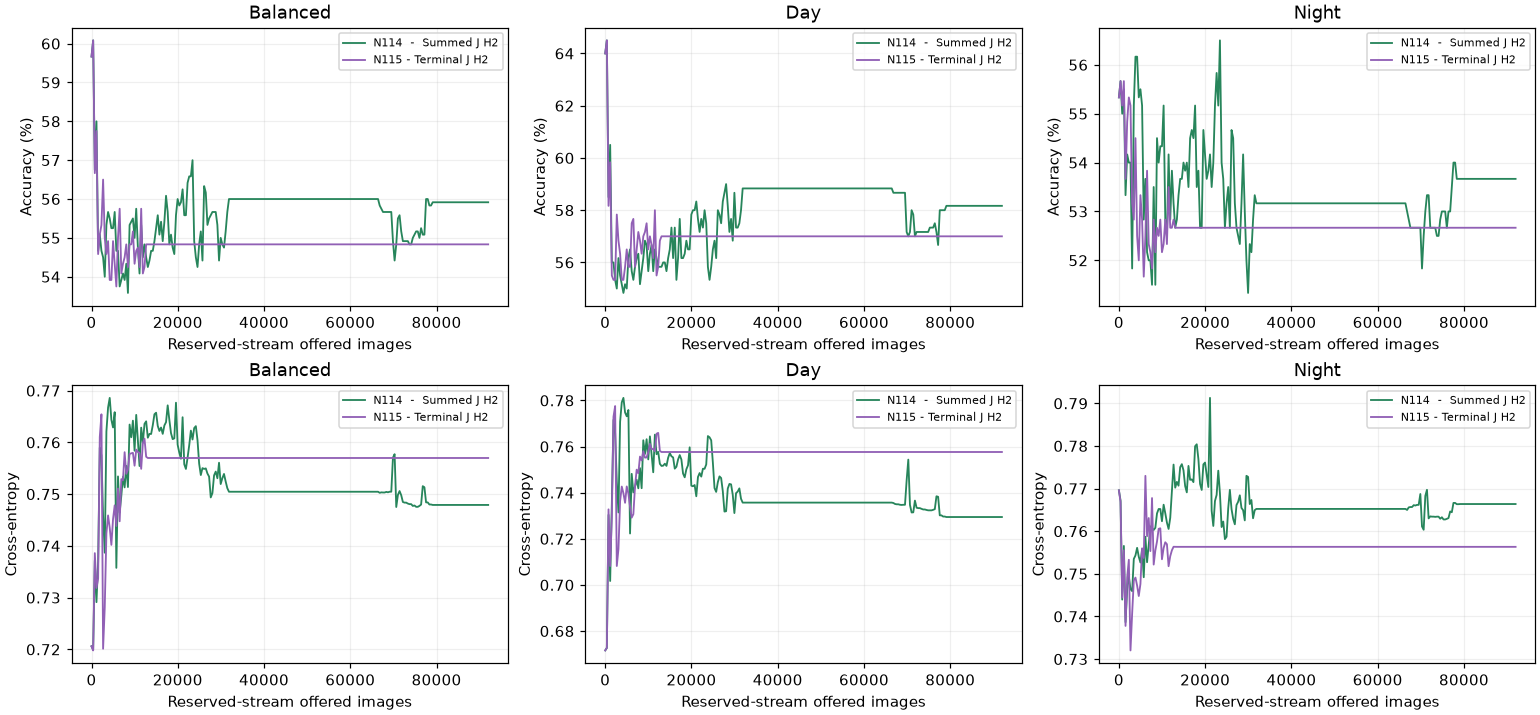



## Previous evaluation: linear task metrics

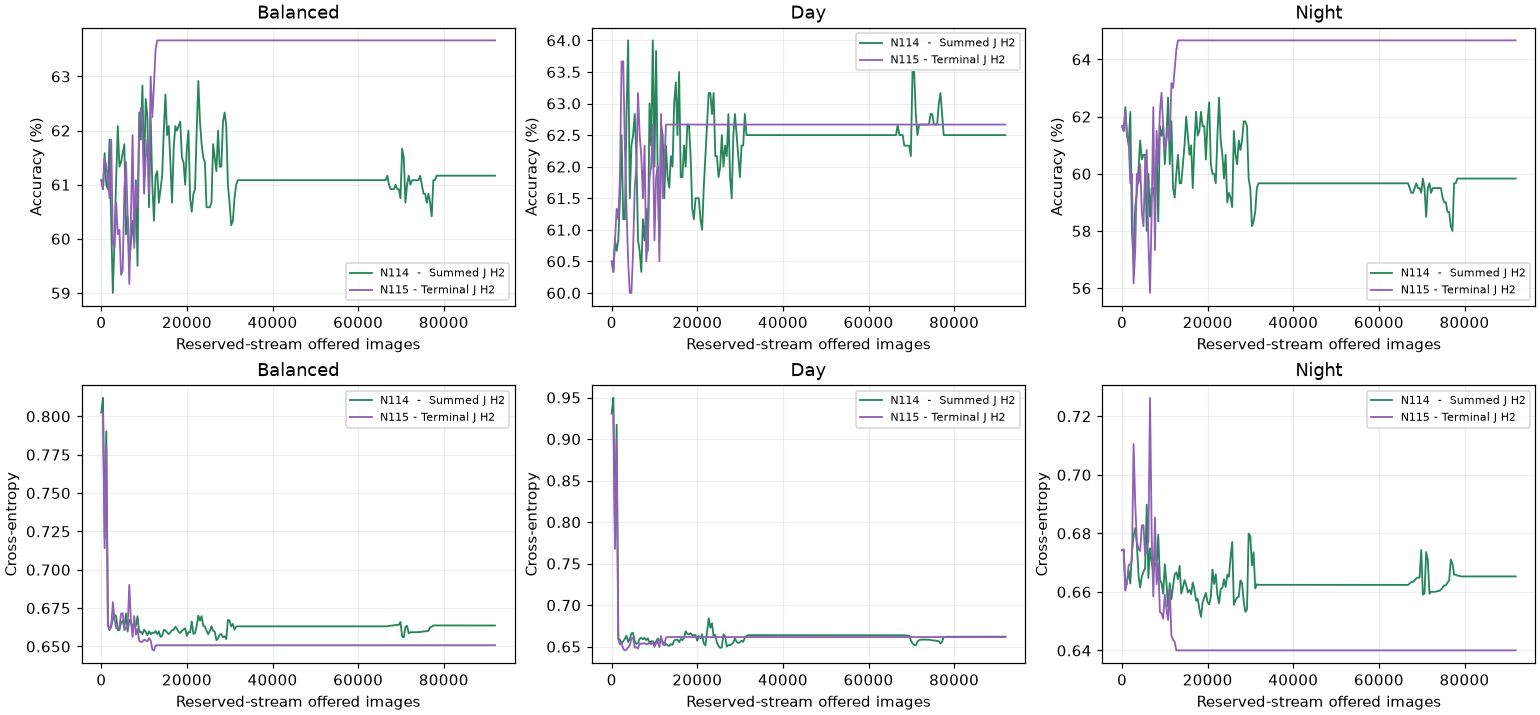



## Previous evaluation: knn task metrics

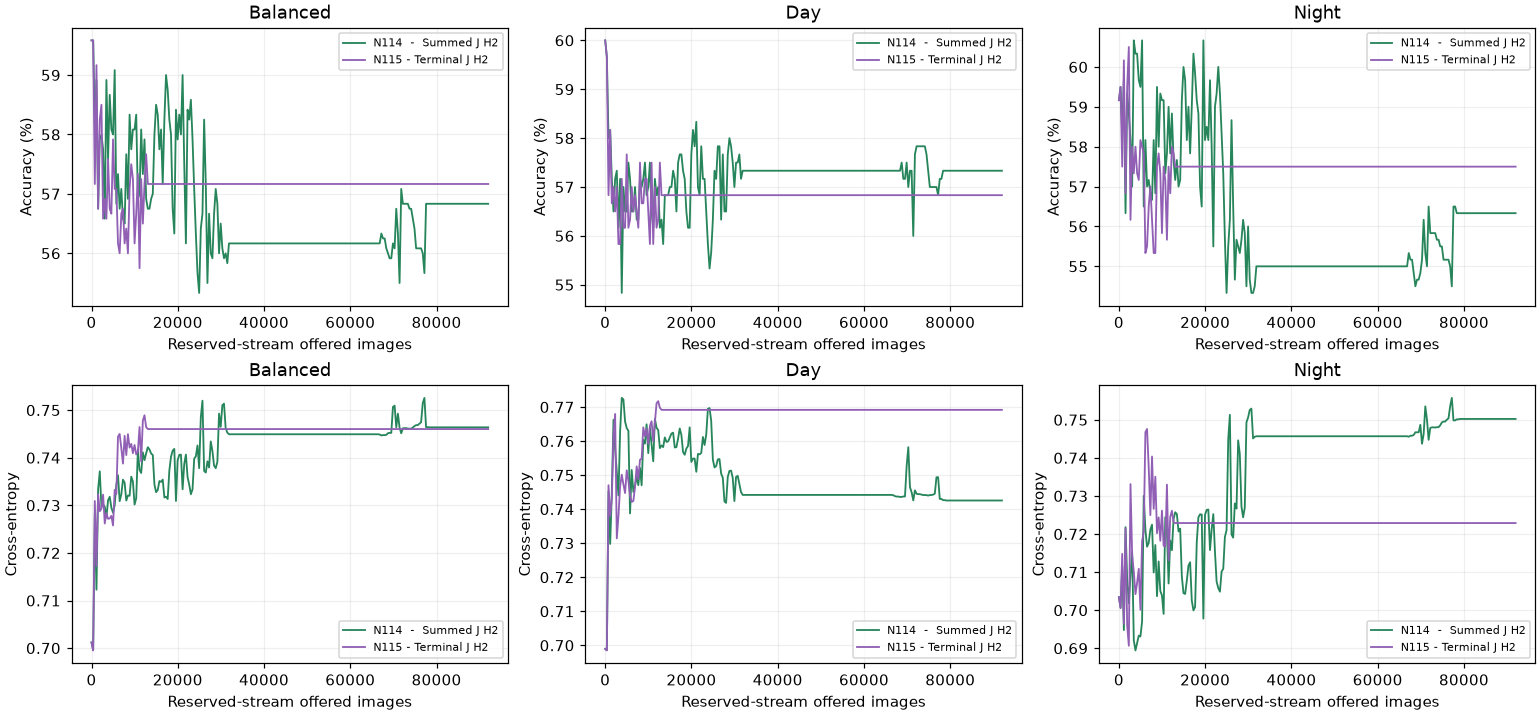



## Additional representation metrics

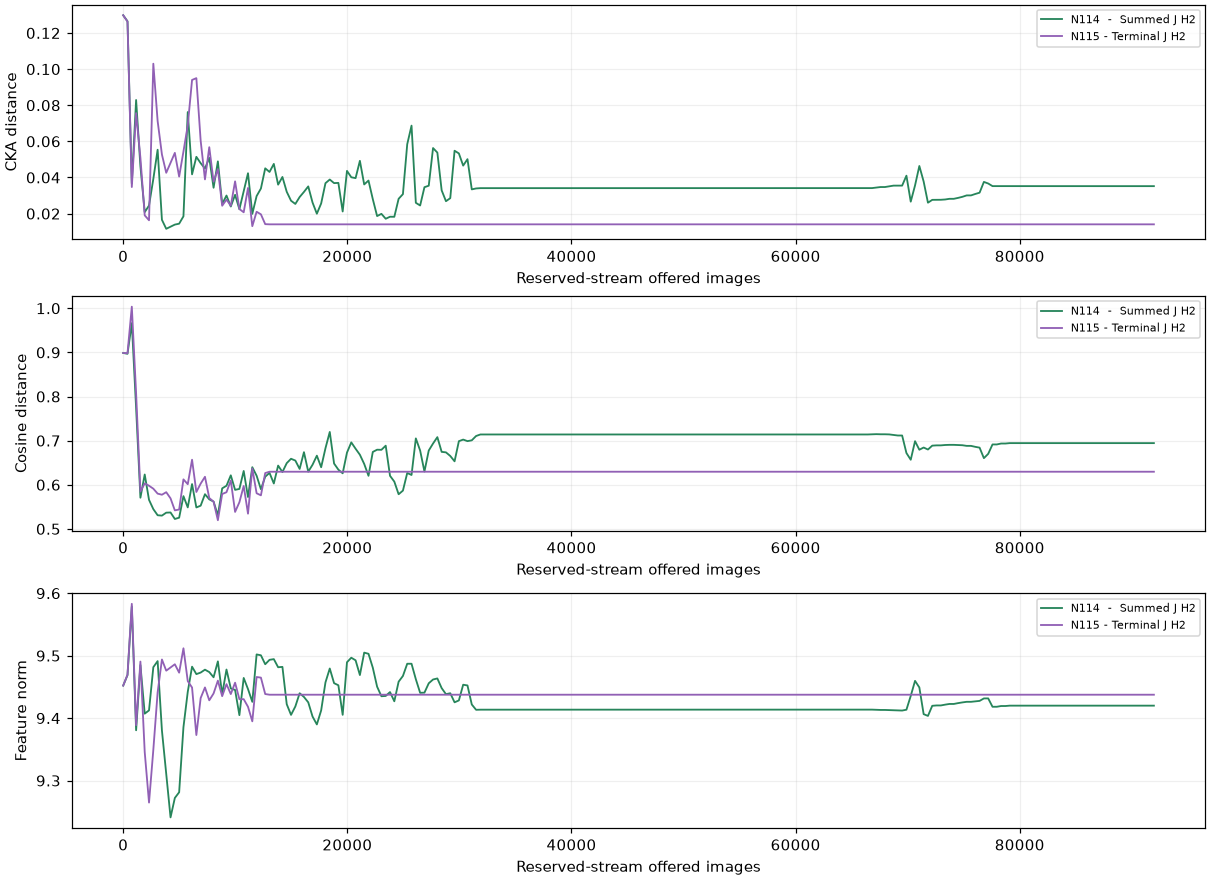



## Secondary evaluation health

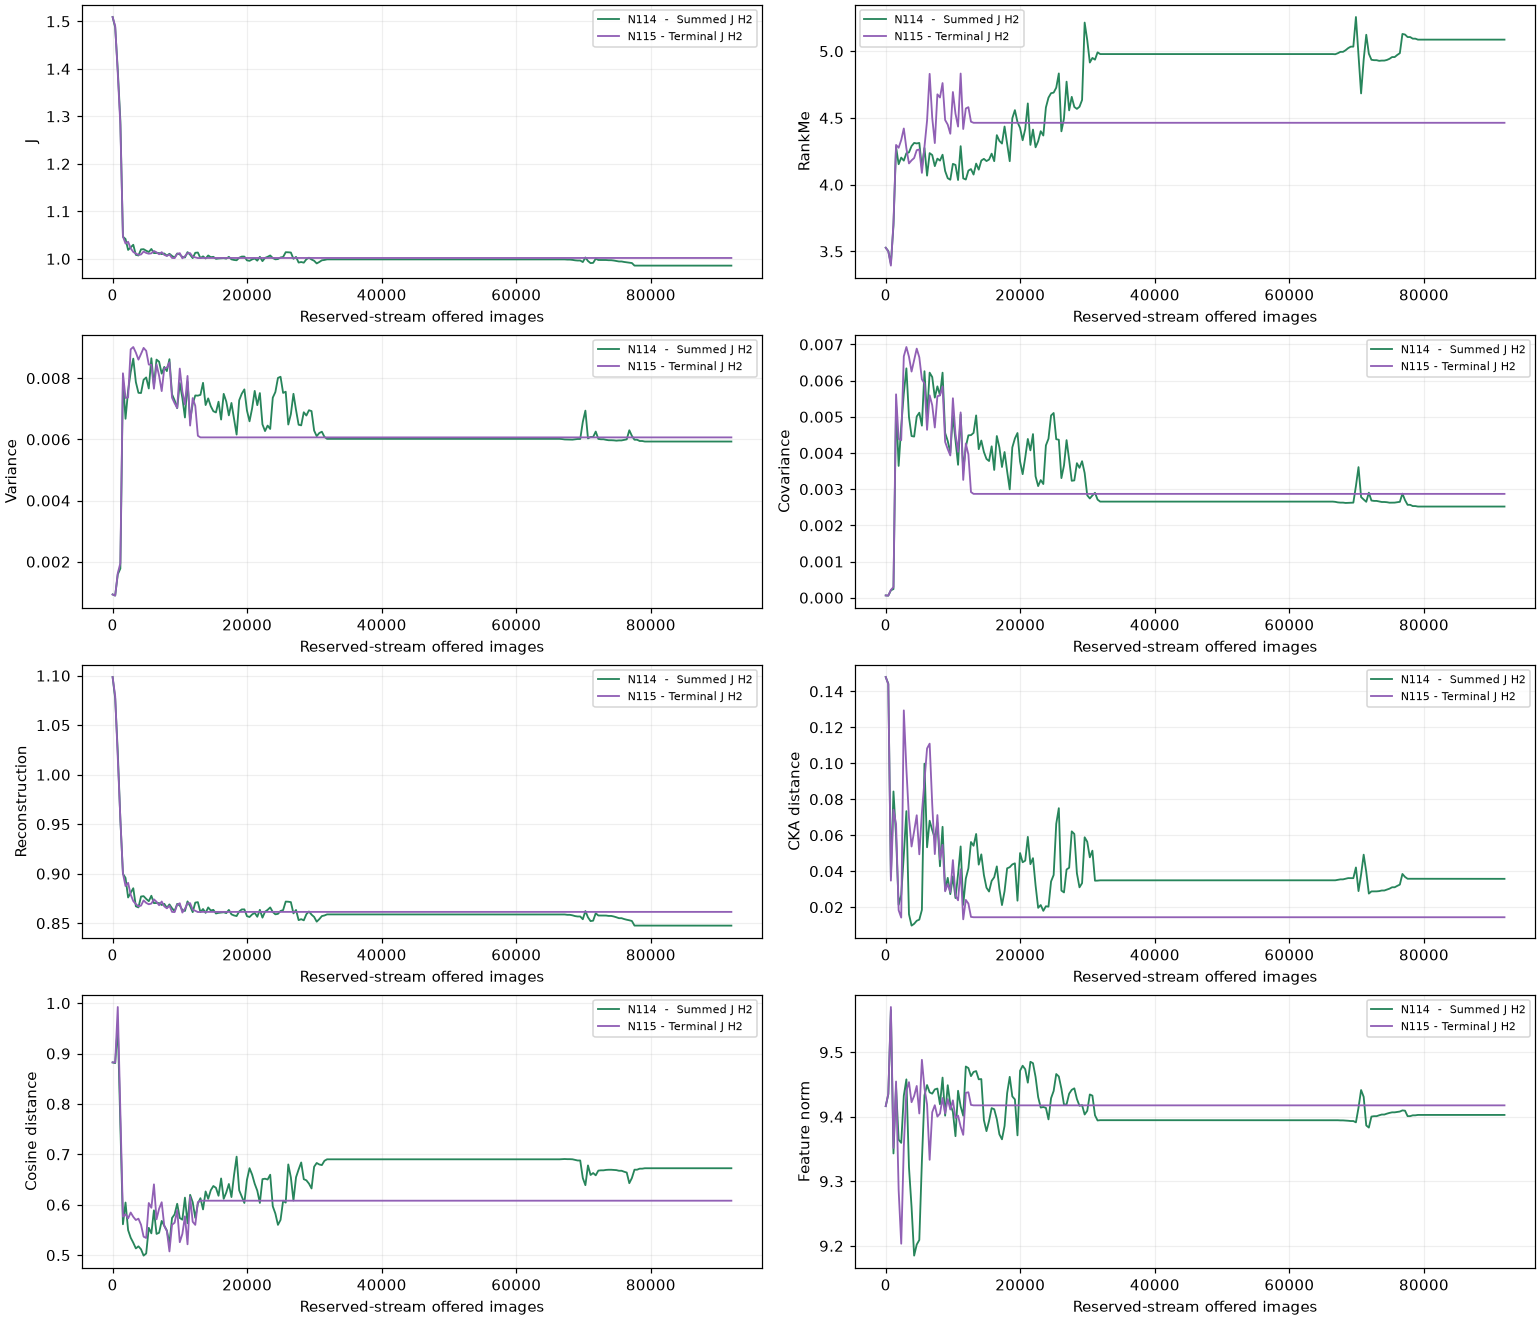



## Actual health versus pre-action causal floors

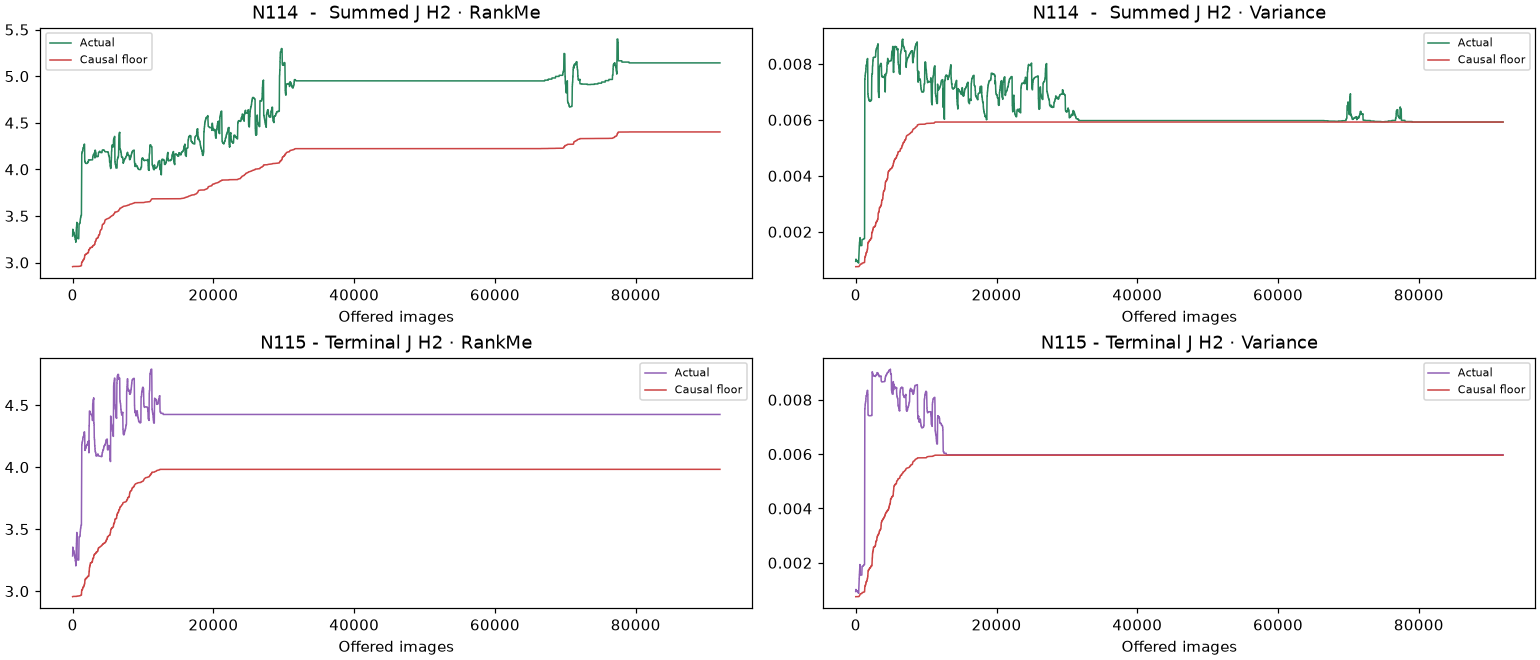



## Prequential chosen-action bound coverage

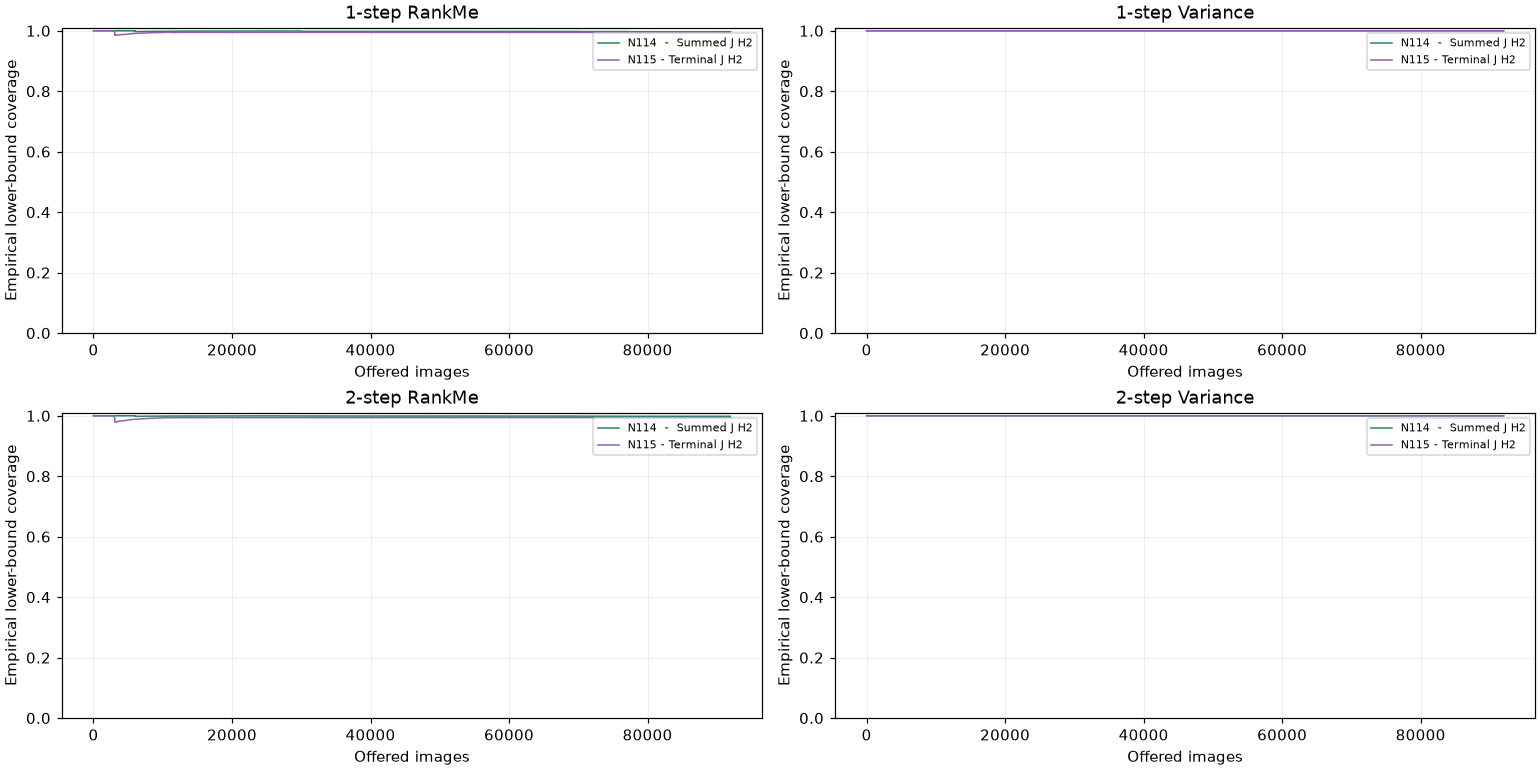

One-step positive updates; two-step nontrivial actual pairs. No claim of policy-independent joint online coverage.

## Filtering, recovery and actual violations

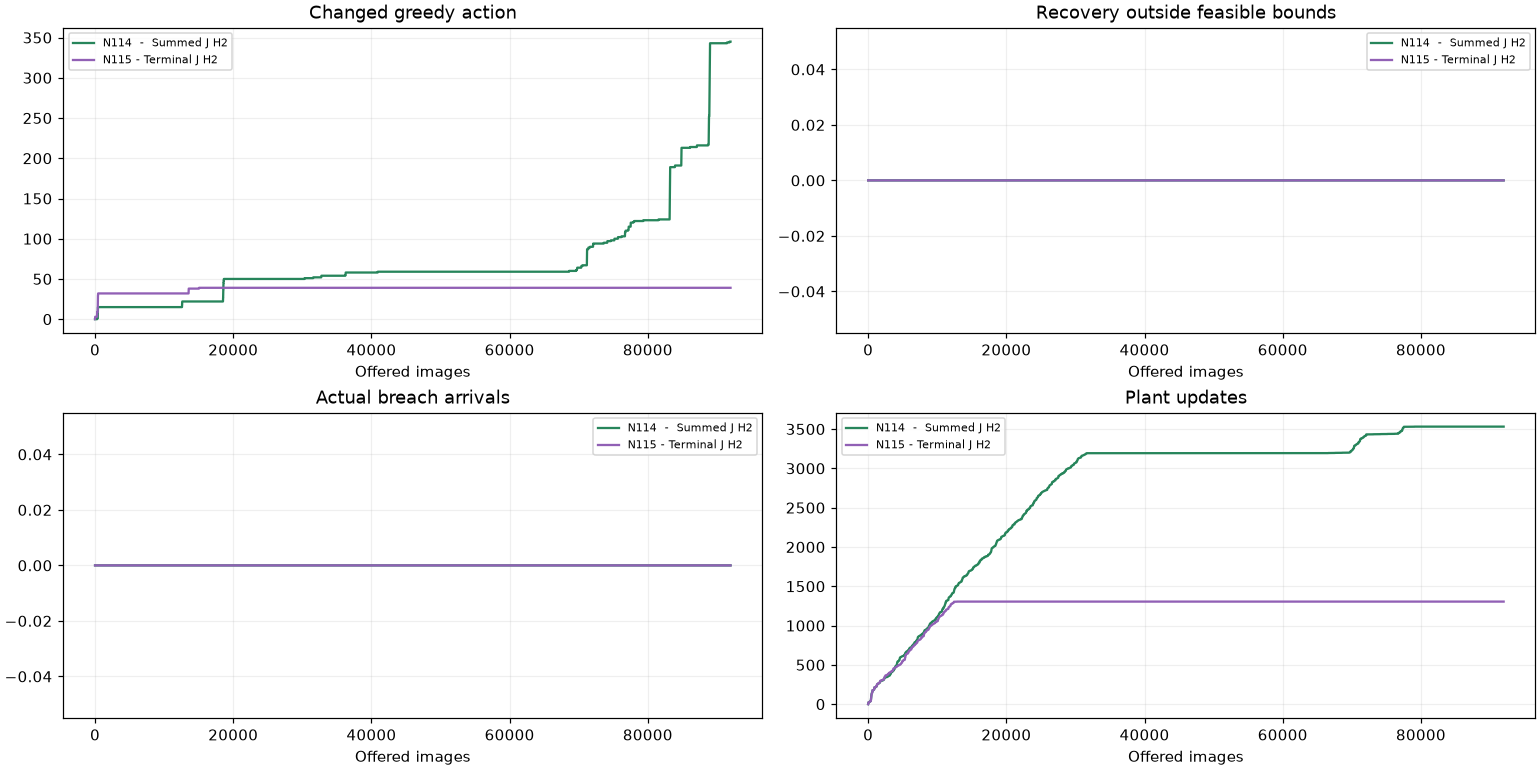



## Direct performance-head prediction error

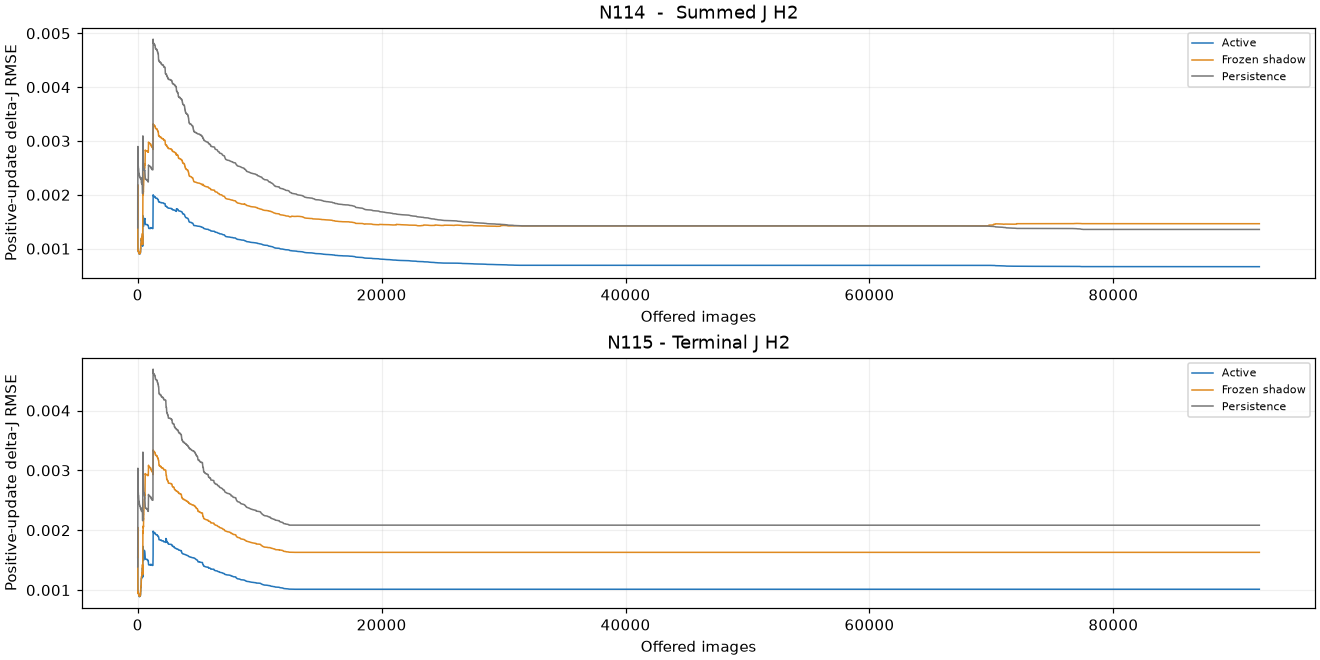



## Audit cost, measured feedback and verified re-entry

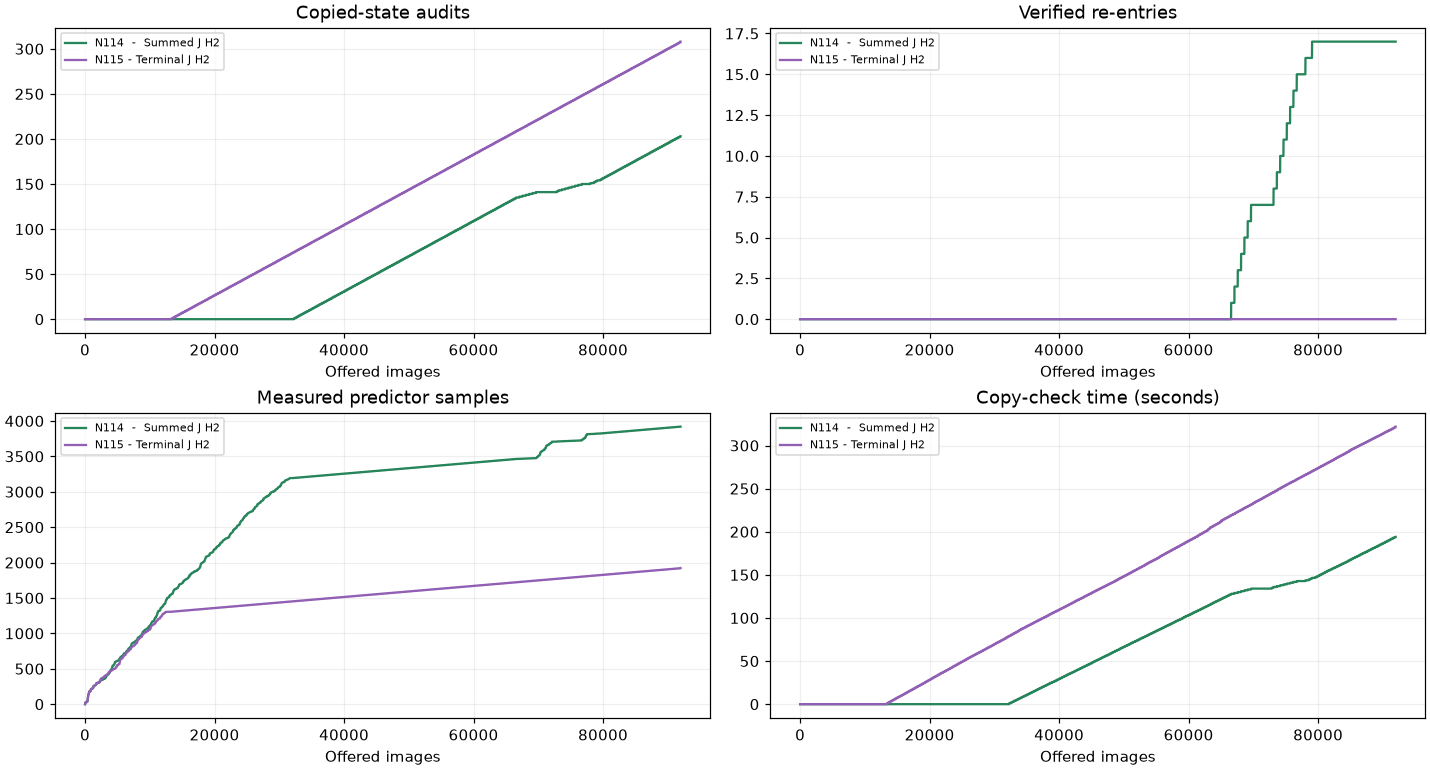

Trials use temporary memory only. Predictor samples include real measurements from uncommitted copies; plant budgets count only committed updates.

## Measured two-update costs and committed re-entry

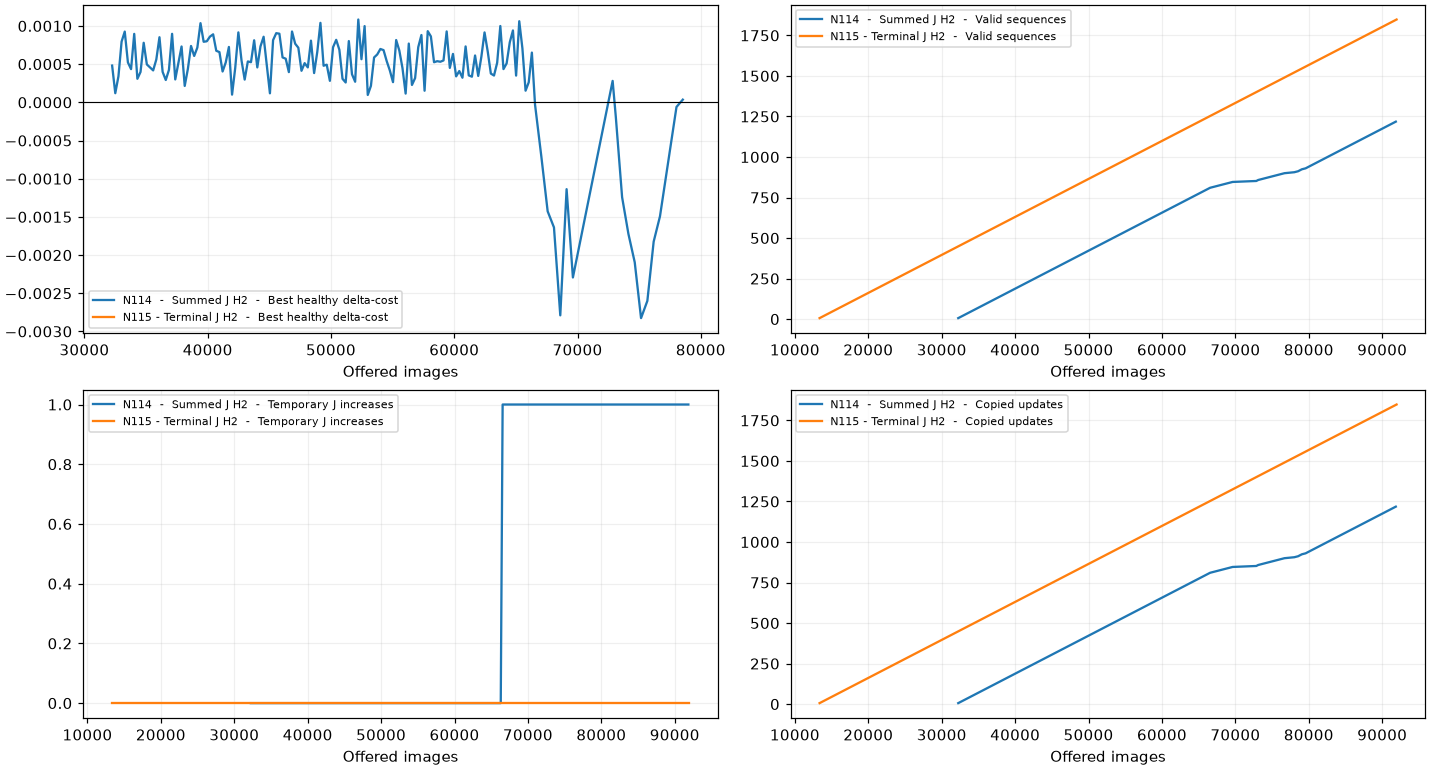

Both measured health states must pass. Only the selected FIRST state is committed; the repeated-image second state is discarded.